# 06 - Análisis de correlaciones
En este Notebook se analizan las correlaciones del conjunto de datos unificado (`data/processed/streets_unified.csv`, Notebook 05).

Los objetivos principales son:
* Estudiar las correlaciones entre las puntuaciones por dimensión (las variables de entrada), por ciudad y por perfil, para ver la relación entre las mismas, cuáles están más correladas que otras y si los perfiles son similares o no.
* Estudiar la relación de cada dimensión con la clase de accesibilidad. Como la clase es ordinal (C < B < A), se utiliza el coeficiente de rangos de Spearman en lugar del de Pearson (https://support.minitab.com/es-mx/minitab/help-and-how-to/statistics/basic-statistics/supporting-topics/correlation-and-covariance/a-comparison-of-the-pearson-and-spearman-correlation-methods/).
* Comprobar si utilizar las variables globales como entrada, o depender únicamente de las de perfiles y dimensiones.

La dimensión de transporte solo existe en Albacete y no está en el conjunto unificado, por lo que no se va a analizar.

## Carga de datos

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from urban_accessibility_ml.config import PROCESSED_DATA_DIR
from urban_accessibility_ml.plots import save_figure as _save_figure, use_style, CMAP_DIV

use_style()

df = pd.read_csv(PROCESSED_DATA_DIR / "streets_unified.csv", dtype={"id_tramo": str})

CITIES = ["Algeciras", "Albacete"]
DIMENSIONS = ["pendiente", "anchura", "pavimento", "cruces", "senalizacion", "iluminacion", "mobiliario"]
PROFILES = ["global", "funcional", "sensorial", "cognitiva"]
# Class of each profile and the total score it is calculated from
CLASS_OF_PROFILE = {"global": "clase_total", "funcional": "clase_funcional", "sensorial": "clase_sensorial", "cognitiva": "clase_cognitiva"}
TOTAL_OF_PROFILE = {"global": "puntuacion_total", "funcional": "puntuacion_total_funcional", "sensorial": "puntuacion_total_sensorial", "cognitiva": "puntuacion_total_cognitiva"}
CLASS_ORDER = {"C": 0, "B": 1, "A": 2}
# Names shown in the figures (the columns of the dataset have no accents)
DIMENSION_LABELS = {"senalizacion": "señalización", "iluminacion": "iluminación"}


def save_figure(fig, name: str):
    """Save the figure in reports/figures/0.06-correlaciones/ to use it in the thesis."""
    _save_figure(name, "0.06-correlaciones", fig=fig)


def dimension_scores(city: str, profile: str) -> pd.DataFrame:
    """Scores per dimension of a city and profile, with the dimension as column name."""
    columns = {f"puntuacion_{d}_{profile}": d for d in DIMENSIONS}
    return df.loc[df["ciudad"] == city, list(columns)].rename(columns=columns)


print(df["ciudad"].value_counts().to_dict())

2026-10-31 12:16:29.010 | INFO     | urban_accessibility_ml.config:<module>:11 - PROJ_ROOT path is: /home/victor-pariente/dev/tfm/tfm-urban-accessibility-ml


{'Albacete': 916, 'Algeciras': 506}


## Correlaciones entre dimensiones
Calculamos la correlación de Spearman entre las puntuaciones de las siete dimensiones. Vamos a empezar por el perfil global, para cada dimensión.

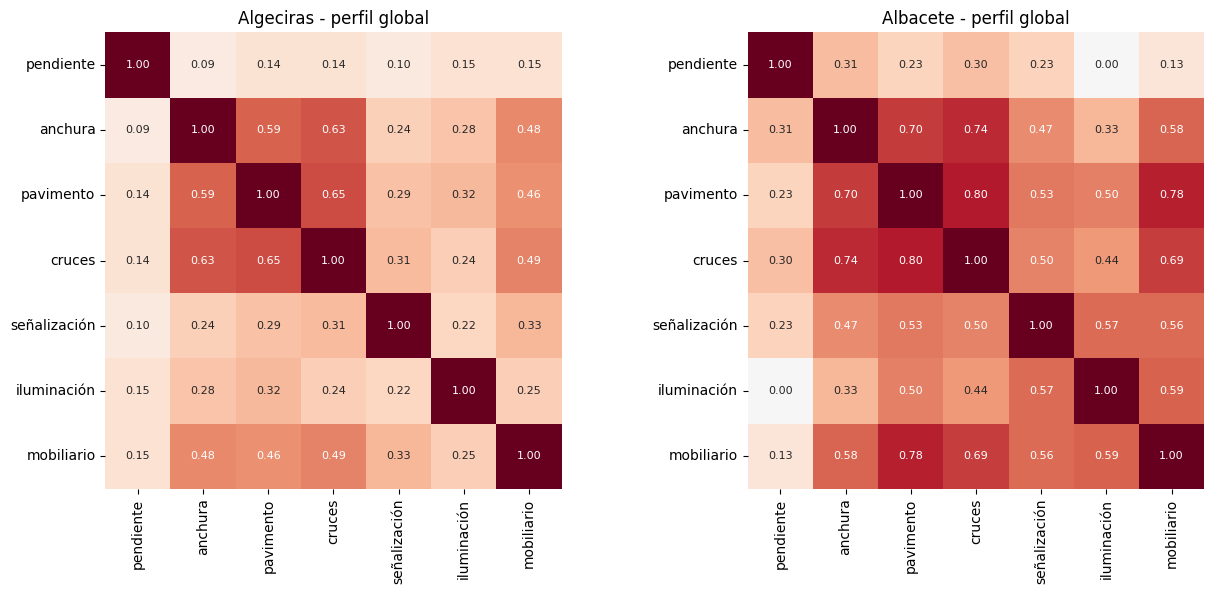

In [2]:
def plot_correlation(ax, corr: pd.DataFrame, title: str):
    corr = corr.rename(index=DIMENSION_LABELS, columns=DIMENSION_LABELS)
    sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap=CMAP_DIV, square=True, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, city in zip(axes, CITIES):
    plot_correlation(ax, dimension_scores(city, "global").corr(method="spearman"), f"{city} - perfil global")
plt.tight_layout()
save_figure(fig, "correlacion_dimensiones_global")
plt.show()

Pares de dimensiones más y menos correlacionados (en valor absoluto) en el perfil global.

In [3]:
def ranked_pairs(corr: pd.DataFrame) -> pd.Series:
    """Pairs of dimensions sorted by absolute correlation, from highest to lowest."""
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    return upper.reindex(upper.abs().sort_values(ascending=False).index).rename("spearman").round(2)


def top_pairs(corr: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    """The n pairs of dimensions with the highest absolute correlation."""
    return ranked_pairs(corr).head(n).to_frame()


def bottom_pairs(corr: pd.DataFrame, n: int = 5) -> pd.DataFrame:
    """The n pairs of dimensions with the lowest absolute correlation (the least related)."""
    return ranked_pairs(corr).tail(n).iloc[::-1].to_frame()


for city in CITIES:
    corr = dimension_scores(city, "global").corr(method="spearman")
    print(f"{city} - más correlacionados")
    display(top_pairs(corr))
    print(f"{city} - menos correlacionados")
    display(bottom_pairs(corr))

Algeciras - más correlacionados


spearman
pavimento cruces          0.65
anchura   cruces          0.63
          pavimento       0.59
cruces    mobiliario      0.49
anchura   mobiliario      0.48

Algeciras - menos correlacionados


spearman
pendiente anchura           0.09
          senalizacion      0.10
          pavimento         0.14
          cruces            0.14
          iluminacion       0.15

Albacete - más correlacionados


spearman
pavimento cruces          0.80
          mobiliario      0.78
anchura   cruces          0.74
          pavimento       0.70
cruces    mobiliario      0.69

Albacete - menos correlacionados


spearman
pendiente iluminacion       0.00
          mobiliario        0.13
          pavimento         0.23
          senalizacion      0.23
          cruces            0.30

Comprobamos que en ambas ciudades, las dimensiones más relacionadas son el pavimento y anchura con los cruces, destacando especialmente en Albacete (pavimento-cruces con 0,80, o anchura-cruces con un 0,74).

También destacan en Albacete pavimento con mobiliario, con 0,78, así como anchura-pavimento con 0,70, o cruces-mobiliario con 0,69.

La correlación en Algeciras es menor, siendo pavimento-cruces la más alta con 0,65, así como anchura-pavimento con 0,59.

En ambos casos, es bastante baja la correlación entre pendiente e iluminación (0,00 en el caso de Albacete), así como pendiente frente a iluminación, mobiliario, pavimento, señalizació, cruces y anchura.

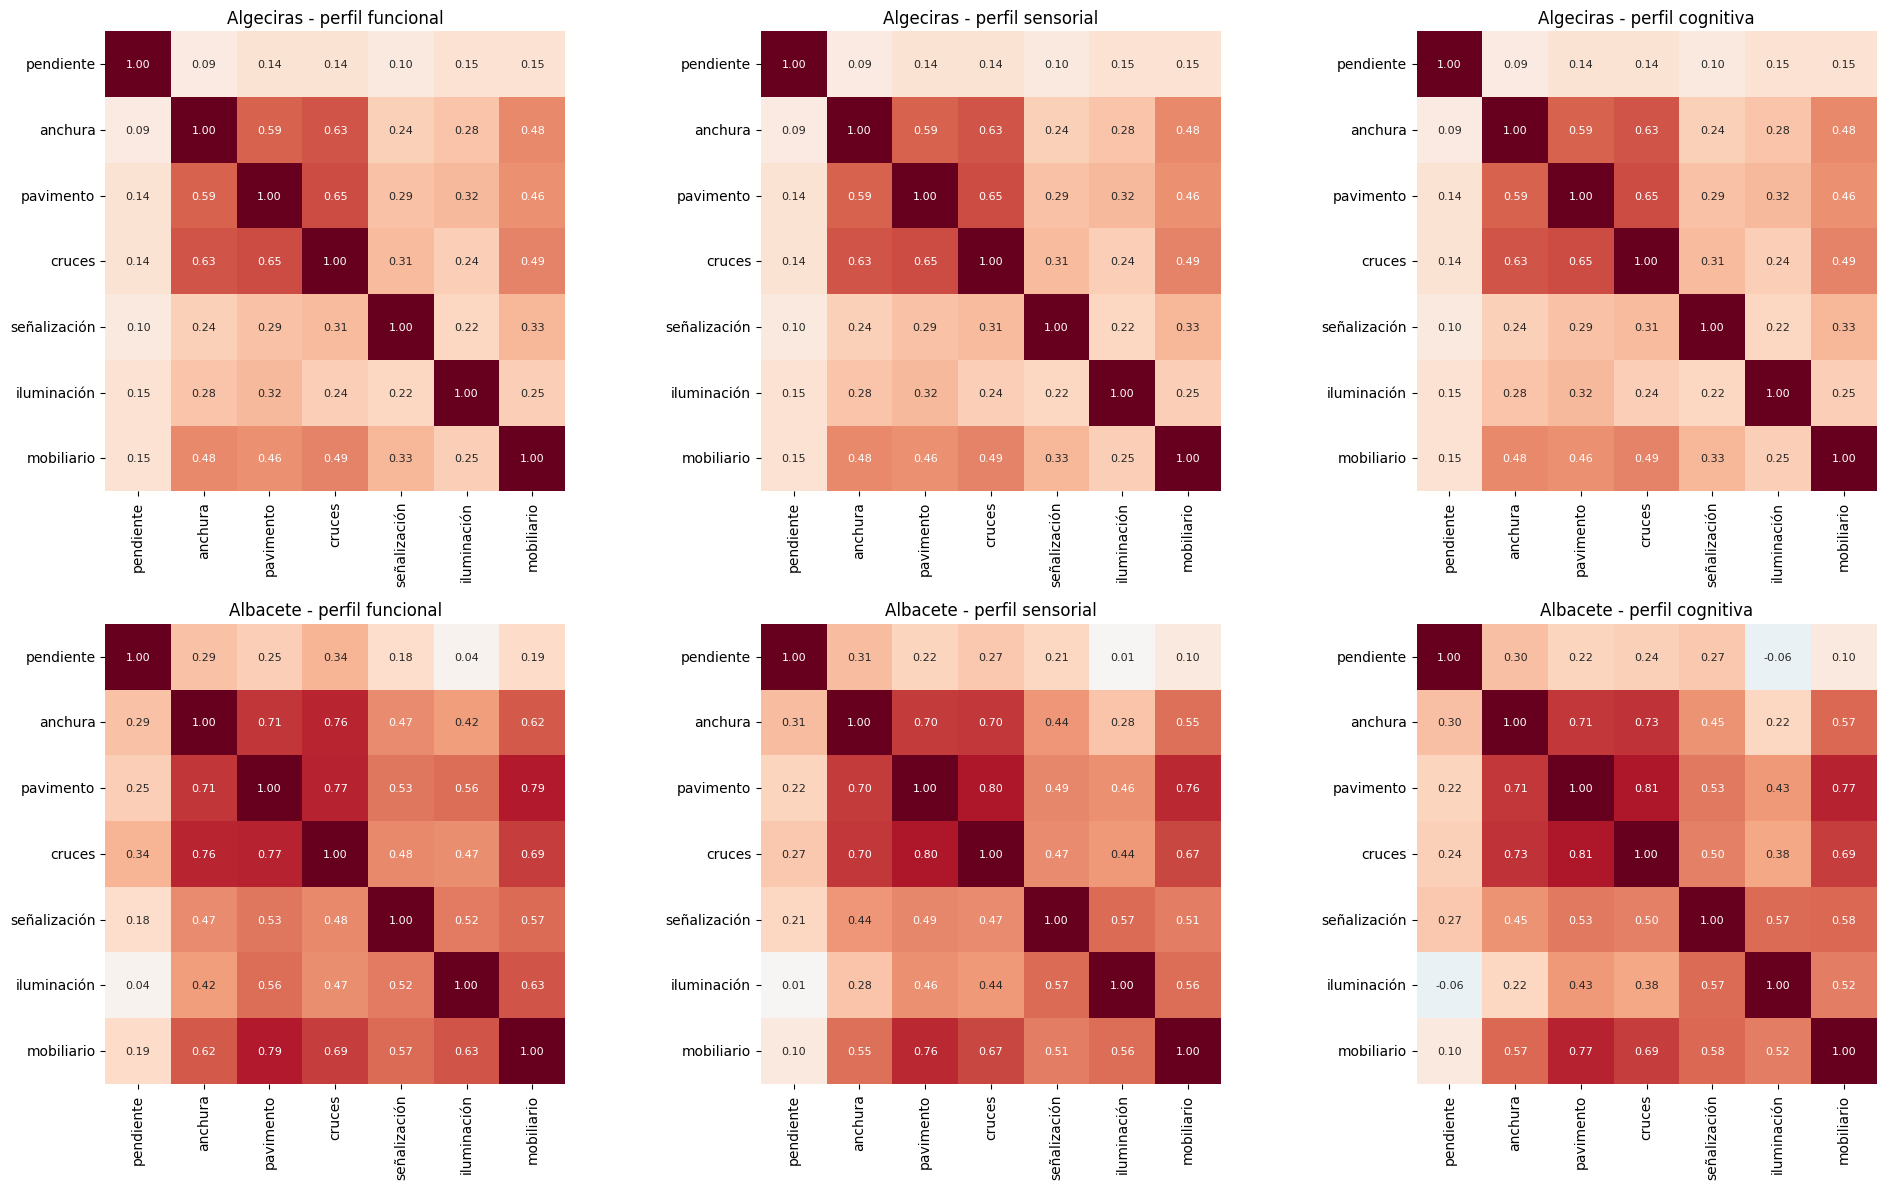

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for row, city in zip(axes, CITIES):
    for ax, profile in zip(row, PROFILES[1:]):
        plot_correlation(ax, dimension_scores(city, profile).corr(method="spearman"), f"{city} - perfil {profile}")
plt.tight_layout()
save_figure(fig, "correlacion_dimensiones_perfiles")
plt.show()

Vemos que los diagramas son bastante similares en cada ciudad, por cada uno de los perfiles funcionales, no viendo aparentemente diferencias significativas.

En Algeciras, lo más correlado es la anchura, pavimento y cruces; con valores entre 0,59 y 0,65. Le sigue el mobiliario con respecto a anchura, pavimento y cruces (entre 0,46 y 0,49). Lo menos correlado con diferencia es la pendiente. No se han encontrado diferencias entre perfiles.

Mientras que en el caso de Albacete, se repiten las mismas correlaciones, aunque con valores más elevados. Anchura pavimento y cruces están entre 0,70 y 0,81. Mobiliario y pavimento cuentan con entre 0,77 y 0,79. En este caso, las diferencias entre perfiles son algo diferentes, pero de manera muy limitada.

### ¿Dicen lo mismo los perfiles?
Para cada dimensión se compara su puntuación en un perfil con la de otro, por ciudad. Una correlación cercana a 1 indicaría que los perfiles aportan casi la misma información.

Con la correlación de Spearman se evalúan las relaciones ordinales, es decir, se ordenan las calles en base a las puntuaciones, y se compara la clasificación ordinal a través de las puntuaciones. Cuanto más cerca se esté de 1, con dos variables se obtendría el mismo orden; cuanto más cerca del 0, menos correlación.
Por ejemplo, un valor de 1 en pavimento entre funcional y sensorial indica que la calle con mejor pavimento funcional es también la de mejor pavimento sensorial, y así con todas las demás.

pendiente  anchura  pavimento  cruces  \
Algeciras funcional - sensorial        1.0     1.00       1.00    1.00   
          funcional - cognitiva        1.0     1.00       1.00    1.00   
          sensorial - cognitiva        1.0     1.00       1.00    1.00   
Albacete  funcional - sensorial        1.0     0.98       0.98    0.94   
          funcional - cognitiva        1.0     0.95       0.95    0.93   
          sensorial - cognitiva        1.0     0.97       0.97    0.97   

                                 senalizacion  iluminacion  mobiliario  total  
Algeciras funcional - sensorial          1.00         1.00        1.00   0.94  
          funcional - cognitiva          1.00         1.00        1.00   0.94  
          sensorial - cognitiva          1.00         1.00        1.00   0.97  
Albacete  funcional - sensorial          0.88         0.89        0.94   0.98  
          funcional - cognitiva          0.71         0.84        0.91   0.96  
          sensorial - cognitiva          0.89         0.90        0.96   0.98

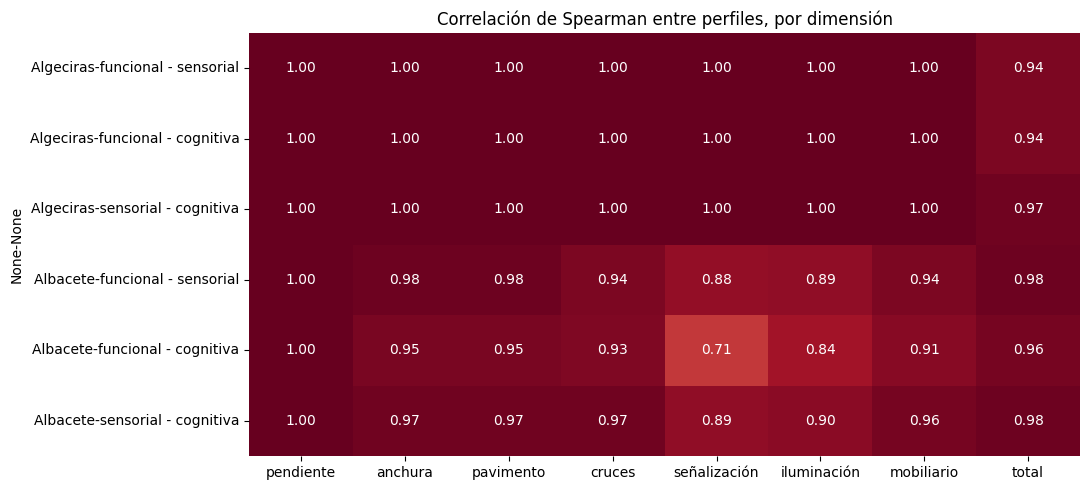

In [5]:
PAIRS = [("funcional", "sensorial"), ("funcional", "cognitiva"), ("sensorial", "cognitiva")]
rows = {}
for city in CITIES:
    sub = df[df["ciudad"] == city]
    for a, b in PAIRS:
        rows[(city, f"{a} - {b}")] = {
            d: sub[f"puntuacion_{d}_{a}"].corr(sub[f"puntuacion_{d}_{b}"], method="spearman") for d in DIMENSIONS
        }
        rows[(city, f"{a} - {b}")]["total"] = sub[TOTAL_OF_PROFILE[a]].corr(sub[TOTAL_OF_PROFILE[b]], method="spearman")
profile_corr = pd.DataFrame(rows).T.round(2)
display(profile_corr)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(profile_corr.rename(columns=DIMENSION_LABELS), annot=True, fmt=".2f", cmap=CMAP_DIV, center=0, vmin=-1, vmax=1, cbar=False, ax=ax)
ax.set_title("Correlación de Spearman entre perfiles, por dimensión")
plt.tight_layout()
save_figure(fig, "correlacion_entre_perfiles")
plt.show()

Como podemos comprobar, la correlación de Spearman es muy elevada en la mayoría de casos, exceptuando la de Albacete cognitiva, en el que hay un valor de 0,71 con respecto a la señalización; o 0,84 con la iluminación.

En el caso de Algeciras, prácticamente todo tiende al 1, por lo que no se aprecia diferencia entre perfiles respecto a las puntuaciones.

Varían algo más, aunque no demasiado, las correlaciones de Albacete, sobre todo en cruces, señalización o iluminación.

## Relación de cada dimensión con la clase de accesibilidad
La clase se codifica como una variable ordinal (C = 0, B = 1, A = 2) y se calcula la correlación de Spearman con la puntuación de cada dimensión. Cada perfil se compara con su propia clase (global con `clase_total`).

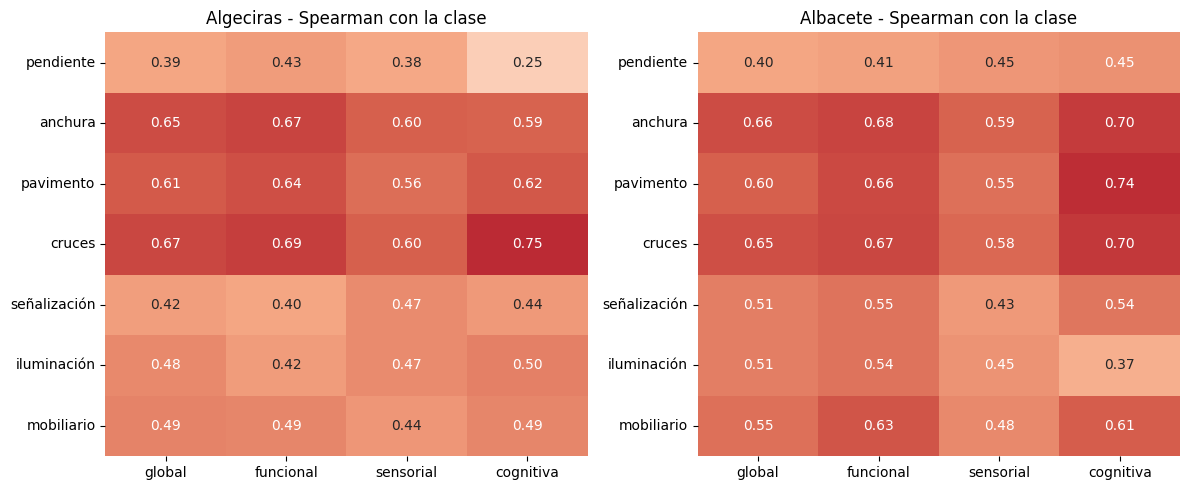

,Algeciras,Albacete
anchura,0.65,0.66
cruces,0.67,0.65
iluminacion,0.48,0.51
mobiliario,0.49,0.55
pavimento,0.61,0.60
pendiente,0.39,0.40
senalizacion,0.42,0.51


In [6]:
def class_correlation(city: str) -> pd.DataFrame:
    """Spearman correlation of each dimension with the ordinal class, for every profile of a city."""
    sub = df[df["ciudad"] == city]
    return pd.DataFrame({
        profile: {
            d: sub[f"puntuacion_{d}_{profile}"].corr(sub[CLASS_OF_PROFILE[profile]].map(CLASS_ORDER), method="spearman")
            for d in DIMENSIONS
        }
        for profile in PROFILES
    })


class_corr = {city: class_correlation(city) for city in CITIES}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, city in zip(axes, CITIES):
    sns.heatmap(class_corr[city].rename(index=DIMENSION_LABELS), annot=True, fmt=".2f", cmap=CMAP_DIV, center=0, vmin=-1, vmax=1, cbar=False, ax=ax)
    ax.set_title(f"{city} - Spearman con la clase")
plt.tight_layout()
save_figure(fig, "correlacion_dimension_clase")
plt.show()

# Dimensions ranked by their correlation with the global class
display(pd.DataFrame({city: class_corr[city]["global"].sort_values(ascending=False) for city in CITIES}).round(2))

Todas las dimensiones tienen correlación positiva con las puntuaciones por perfiles.

Destacan los cruces, anchura o pavimento, con correlaciones de entre 0,55 y 0,75 según el perfil (en el perfil global, entre 0,60 y 0,67). Mientras que en el caso de la pendiente o la señalización son más bajas.

Se observan diferencias entre ciudades:
- En cognitiva, Algeciras tiene como orden: cruces (0,75), pavimento (0,62), seguida de anchura (0,59), siendo la pendiente la más baja (0,25), seguida de señalización (0,44); mientras que Albacete tiene más alto pavimento (0,74), seguido de anchura y cruces (0,70), mientras que la iluminación es la más baja (0,37), seguida de pendiente (0,45).
- En sensorial los datos son bastante similares entre ciudades, siendo algo más baja la correlación de pendiente en Algeciras (0,38 respecto a 0,45 de Albacete).
- Mientras que en funcional, Albacete tiene las correlaciones de señalización, iluminación o mobiliario más elevadas.

No hay ninguna dimensión que explique la clase por sí sola, atendiendo a los valores de las correlaciones (ninguna se acerca al 1).

Pendiente es la dimensión más diferente respecto a las demás.

## Comprobación de que las puntuaciones totales no son entrada
La clase de cada perfil se calcula a partir de su puntuación total (tercios de la escala 0-1: C por debajo de 1/3, B hasta 2/3 y A desde 2/3). Si una puntuación total se usara como variable de entrada, el modelo solo tendría que aprender de ella.

Vamos a comprobar primero que cada clase es exactamente la que sale de su puntuación total.

In [7]:
def thirds(score: pd.Series) -> pd.Series:
    return pd.Series(np.select([score < 1 / 3, score < 2 / 3], ["C", "B"], default="A"), index=score.index)


# Every class must be exactly the thirds of its total score
for profile in PROFILES:
    assert (thirds(df[TOTAL_OF_PROFILE[profile]]) == df[CLASS_OF_PROFILE[profile]]).all(), profile
print("Todas las clases coinciden con los tercios de su puntuación total (en las dos ciudades).")

Todas las clases coinciden con los tercios de su puntuación total (en las dos ciudades).


Y por último, definimos las columnas de entrada: las puntuaciones por dimensión, dejando fuera las cuatro puntuaciones totales. Además, vemos cuánto se parece cada total a la clase frente a la mejor dimensión, para justificar por qué las dejamos fuera de las variables de entrada.

In [8]:
# Input columns: the scores per dimension; the total scores are left out because the class is calculated from them
FEATURES = [c for c in df.columns if c.startswith("puntuacion_") and not c.startswith("puntuacion_total")]
print(f"{len(FEATURES)} columnas de entrada = {len(DIMENSIONS)} dimensiones x {len(PROFILES)} perfiles.")

rows = []
for profile in PROFILES:
    for city in CITIES:
        sub = df[df["ciudad"] == city]
        by_dimension = class_corr[city][profile]  # correlation of each dimension with the class of this profile
        rows.append({
            "perfil": profile,
            "ciudad": city,
            "correlacion_total": sub[TOTAL_OF_PROFILE[profile]].corr(sub[CLASS_OF_PROFILE[profile]].map(CLASS_ORDER), method="spearman"),
            "correlacion_mejor_dimension": by_dimension.max(),
            "mejor_dimension": by_dimension.idxmax(),
        })
comparison = pd.DataFrame(rows).set_index(["perfil", "ciudad"]).round(2)
display(comparison)

28 columnas de entrada = 7 dimensiones x 4 perfiles.


correlacion_total  correlacion_mejor_dimension  \
perfil    ciudad                                                      
global    Algeciras               0.88                         0.67   
          Albacete                0.72                         0.66   
funcional Algeciras               0.89                         0.69   
          Albacete                0.76                         0.68   
sensorial Algeciras               0.86                         0.60   
          Albacete                0.67                         0.59   
cognitiva Algeciras               0.87                         0.75   
          Albacete                0.87                         0.74   

                    mejor_dimension  
perfil    ciudad                     
global    Algeciras          cruces  
          Albacete          anchura  
funcional Algeciras          cruces  
          Albacete          anchura  
sensorial Algeciras         anchura  
          Albacete          anchura  
cognitiva Algeciras          cruces  
          Albacete        pavimento

La tabla compara, para cada perfil y ciudad, dos correlaciones con la clase: la de la puntuación total (`correlacion_total`) y la de la dimensión que más se parece a la clase (`correlacion_mejor_dimension`, con su nombre en `mejor_dimension`). Cuanto más cerca de 1, más correladas están.

En todos los casos la puntuación total está más correlada con la clase que cualquier dimensión por separado (por ejemplo, 0,88 frente a 0,67 en Algeciras con el perfil global, donde la mejor dimensión es cruces). Es decir, las dimensiones solo aportan una parte de la clase, no toda en su conjunto.

Por eso el total no se usa como columna de entrada: acertaría utilizando un algoritmo simple y no comprobando la relación entre las variables. De esta manera, los modelos tendrán que combinar las dimensiones para obtener la clase final.

## Conclusiones
* **Dimensiones entre sí:** las que más correladas están son pavimento, cruces y anchura (hasta 0,65 en Algeciras y 0,80 en Albacete). La que menos es pendiente, que aporta información distinta al resto.
* **Perfiles:** los perfiles funcional, sensorial y cognitivo ordenan las calles casi igual para una dimensión concreta, así que no hay diferencias significativas y aportan casi lo mismo entre ellas.
* **Dimensiones y clase:** todas las dimensiones tienen correlación positiva con la clase. Destacan los cruces, la anchura y el pavimento, con correlaciones de entre 0,55 y 0,75 según el perfil (en el perfil global, entre 0,60 y 0,67). Mientras que en el caso de la pendiente o la señalización son más bajas.
* **Totales:** cada clase sale exactamente de los tercios de su puntuación total. La puntuación total se parece más a la clase que cualquier dimensión por separado (por ejemplo, 0,88 frente a 0,67 en Algeciras con el perfil global), así que no la usamos como columna de entrada, porque le daríamos la respuesta directamente al modelo.
